# Mechanistic Non-Identifiability in Minimal Biological Models
### Can two genuinely different regulatory mechanisms be invisible to each other at steady state?

Compares two structurally different, individually real single-gene negative-autoregulation mechanisms
(repression acting on the gene's own *production* vs. on its own *degradation*). Proves, symbolically,
that both produce an *identical* steady-state dose-response relationship (a real structural
non-identifiability, not a parameter-specific coincidence) — then constructs and numerically validates a
specific *transient* (time-course) measurement protocol that provably tells them apart. A separate
profile-likelihood check confirms this isn't a generic "everything is unmeasurable" artifact: ordinary
rate parameters *within* one model remain practically identifiable from a steady-state dose-response curve
alone.


## Step 0 — Environment setup

In [1]:
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize
from scipy.integrate import solve_ivp

np.set_printoptions(precision=4, suppress=True)
np.random.seed(42)
print("numpy:", np.__version__)
print("sympy:", sp.__version__)


numpy: 2.4.6
sympy: 1.14.0


## Step 1 — Define both candidate ODE models

A gene product `x` represses its own expression. **Model A** (feedback on *production*): the repression
term multiplies the *synthesis* rate, degradation stays a plain first-order process. **Model B** (feedback
on *degradation*): synthesis stays a plain constant rate, the repression term instead multiplies the
*removal* rate. Both are real, documented regulatory strategies (self-blocking promoter vs. self-triggered
targeted proteolysis).

In nondimensional form (Hill threshold `K`, cooperativity `n`, max production `alpha`, first-order rate
constant `gamma`):

```
Model A:  dx/dt = alpha/(1+(x/K)**n) - gamma*x
Model B:  dx/dt = alpha - gamma*x*(1+(x/K)**n)
```


In [2]:
def fA(x, alpha, K, n, gamma):
    return alpha/(1+(x/K)**n) - gamma*x  # alpha/(1+(x/K)**n) - gamma*x

def fB(x, alpha, K, n, gamma):
    return alpha - gamma*x*(1+(x/K)**n)  # alpha - gamma*x*(1+(x/K)**n)

print("fA(0.5, 1,1,4,1) =", fA(0.5,1,1,4,1))
print("fB(0.5, 1,1,4,1) =", fB(0.5,1,1,4,1))


fA(0.5, 1,1,4,1) = 0.4411764705882353
fB(0.5, 1,1,4,1) = 0.46875


## Step 2 — Symbolic steady-state comparison (hero result 1)

At steady state, production rate equals removal rate. Setting each model's right-hand side to zero and
solving for `alpha` in terms of the steady state `x*` gives each model's real steady-state input-output
relationship. If the two resulting expressions for `alpha` are *symbolically identical* (not just
numerically close at one parameter set), that is a real, exact proof of structural non-identifiability
from steady-state data alone — true at every parameter value, not a coincidence.


In [3]:
x, K, n, alpha, gamma = sp.symbols('x K n alpha gamma', positive=True)

fA_expr = alpha/(1+(x/K)**n) - gamma*x  # alpha/(1+(x/K)**n) - gamma*x
fB_expr = alpha - gamma*x*(1+(x/K)**n)  # alpha - gamma*x*(1+(x/K)**n)

alphaA_ss = sp.solve(sp.Eq(fA_expr, 0), alpha)[0]  # sp.solve(sp.Eq(fA_expr, 0), alpha)[0]
alphaB_ss = sp.solve(sp.Eq(fB_expr, 0), alpha)[0]  # sp.solve(sp.Eq(fB_expr, 0), alpha)[0]

print("Model A steady-state relation: alpha =", sp.simplify(alphaA_ss))
print("Model B steady-state relation: alpha =", sp.simplify(alphaB_ss))

difference = sp.simplify(alphaA_ss - alphaB_ss)  # sp.simplify(alphaA_ss - alphaB_ss)
print("\nSymbolic difference (expect exactly 0):", difference)
print("Steady states structurally identical for ALL parameter values:", difference == 0)


Model A steady-state relation: alpha = gamma*x*(K**n + x**n)/K**n
Model B steady-state relation: alpha = gamma*x*(K**n + x**n)/K**n

Symbolic difference (expect exactly 0): 0
Steady states structurally identical for ALL parameter values: True


## Step 3 — Symbolic linearization comparison (hero result 2)

The steady states agree for every parameter value, but each model's *local relaxation rate* around that
steady state (the derivative of the right-hand side w.r.t. `x`, evaluated at the steady state) need not.
Differentiate both right-hand sides w.r.t. `x`, substitute the *shared* steady-state relation
(`alpha = gamma*x*(1+(x/K)**n)`) into each derivative, simplify, and compare.


In [4]:
dfA = sp.diff(fA_expr, x)  # sp.diff(fA_expr, x)
dfB = sp.diff(fB_expr, x)  # sp.diff(fB_expr, x)

alpha_expr = gamma*x*(1+(x/K)**n)

dfA_ss = sp.simplify(dfA.subs(alpha, alpha_expr))  # sp.simplify(dfA.subs(alpha, alpha_expr))
dfB_ss = sp.simplify(dfB.subs(alpha, alpha_expr))  # sp.simplify(dfB.subs(alpha, alpha_expr))

print("Model A linearized relaxation rate at steady state:", dfA_ss)
print("Model B linearized relaxation rate at steady state:", dfB_ss)

diff_linear = sp.simplify(dfA_ss - dfB_ss)  # sp.simplify(dfA_ss - dfB_ss)
print("\nDifference (expect NONZERO in general):", diff_linear)
print("Equal only in the trivial x->0 limit -- check by substituting x=0:", diff_linear.subs(x, 0))


Model A linearized relaxation rate at steady state: gamma*(-K**n - n*x**n - x**n)/(K**n + x**n)
Model B linearized relaxation rate at steady state: gamma*(-K**n - n*x**n - x**n)/K**n

Difference (expect NONZERO in general): gamma*(x/K)**n*(K**n + n*x**n + x**n)/(K**n + x**n)
Equal only in the trivial x->0 limit -- check by substituting x=0: 0


## Step 4 — Representative parameters: numeric root-find + eigenvalue check

Pick `K=1, gamma=1, n=4`, and a target steady state `xstar=1.2`. Compute the matching `alpha` from the
shared steady-state relation. Confirm via `scipy.optimize.brentq` on both models separately that each
really does have a root at `xstar` for this `alpha`. Then evaluate the two linearization expressions from
Step 3 numerically at `xstar` to get each model's real local relaxation rate.


In [5]:
K_val, gamma_val, n_val = 1.0, 1.0, 4.0
xstar = 1.2
alpha_val = gamma_val*xstar*(1+(xstar/K_val)**n_val)  # gamma_val*xstar*(1+(xstar/K_val)**n_val)
print("alpha chosen:", alpha_val)

rootA = brentq(fA, 1e-6, 10, args=(alpha_val, K_val, n_val, gamma_val))  # brentq(fA, 1e-6, 10, args=(alpha_val, K_val, n_val, gamma_val))
rootB = brentq(fB, 1e-6, 10, args=(alpha_val, K_val, n_val, gamma_val))  # brentq(fB, 1e-6, 10, args=(alpha_val, K_val, n_val, gamma_val))
print("rootA:", rootA, " rootB:", rootB, " both match target xstar:", xstar)

dfA_func = sp.lambdify((x, K, n, gamma), dfA_ss, "numpy")  # sp.lambdify((x, K, n, gamma), dfA_ss, "numpy")
dfB_func = sp.lambdify((x, K, n, gamma), dfB_ss, "numpy")  # sp.lambdify((x, K, n, gamma), dfB_ss, "numpy")

lamA = float(dfA_func(xstar, K_val, n_val, gamma_val))  # float(dfA_func(xstar, K_val, n_val, gamma_val))
lamB = float(dfB_func(xstar, K_val, n_val, gamma_val))  # float(dfB_func(xstar, K_val, n_val, gamma_val))
print(f"\nlamA (Model A relaxation rate) = {lamA:.4f}")
print(f"lamB (Model B relaxation rate) = {lamB:.4f}")
print(f"Ratio |lamB/lamA| = {abs(lamB/lamA):.4f}  (how many times faster Model B relaxes)")


alpha chosen: 3.6883199999999996
rootA: 1.2  rootB: 1.2  both match target xstar: 1.2

lamA (Model A relaxation rate) = -3.6986
lamB (Model B relaxation rate) = -11.3680
Ratio |lamB/lamA| = 3.0736  (how many times faster Model B relaxes)


## Step 5 — Simulate the distinguishing transient + validate it numerically (the hero step)

Simulate a real step-response time course for both models with `scipy.integrate.solve_ivp`
(`method="Radau"`, tight `rtol`/`atol` — Model B's relaxation is stiffer), starting far below steady state
and integrating to `t=3.0`. `solve_ivp` always calls the right-hand-side function with a state *vector*
and (for `Radau`) needs it to always return a vector too, even for a 1D system.

A residual-magnitude-windowed exponential fit (`numpy.polyfit` on `log|x(t)-x*|` restricted to a residual
band, not a fixed time window) recovers each model's real relaxation rate from its simulated trajectory —
a fixed time window can miss the genuinely linear decay regime for one or both models depending on how far
apart their two time constants are. Confirming the fitted rate matches the analytic eigenvalue from Step 4
is the real, constructive validation that a transient measurement (not a steady-state one) distinguishes
the two mechanisms.


In [7]:
x0 = 0.01*xstar
t_eval = np.linspace(0, 3.0, 200000)

solA = solve_ivp(lambda t, xv: [fA(xv[0], alpha_val, K_val, n_val, gamma_val)], (0, 3.0), [x0], t_eval=t_eval, method="Radau", rtol=1e-13, atol=1e-15)  # lambda t, xv: [fA(xv[0], alpha_val, K_val, n_val, gamma_val)]
solB = solve_ivp(lambda t, xv: [fB(xv[0], alpha_val, K_val, n_val, gamma_val)], (0, 3.0), [x0], t_eval=t_eval, method="Radau", rtol=1e-13, atol=1e-15)  # lambda t, xv: [fB(xv[0], alpha_val, K_val, n_val, gamma_val)]

xA_traj = solA.y[0]  # solA.y[0]
xB_traj = solB.y[0]  # solB.y[0]

def fit_rate(t, xt, xstar_val, resid_hi=1e-2, resid_lo=1e-5):
    resid = np.abs(xt-xstar_val)  # np.abs(xt - xstar_val)
    mask = (resid < resid_hi) & (resid > resid_lo)  # (resid < resid_hi) & (resid > resid_lo)
    slope, intercept = np.polyfit(t[mask], np.log(resid[mask]), 1)  # np.polyfit(t[mask], np.log(resid[mask]), 1)
    return slope

rateA_fit = fit_rate(t_eval, xA_traj, xstar)  # fit_rate(t_eval, xA_traj, xstar)
rateB_fit = fit_rate(t_eval, xB_traj, xstar)  # fit_rate(t_eval, xB_traj, xstar)

print(f"Model A: fitted relaxation rate = {rateA_fit:.4f}   analytic lamA = {lamA:.4f}")
print(f"Model B: fitted relaxation rate = {rateB_fit:.4f}   analytic lamB = {lamB:.4f}")
print(f"\nPercent error A: {100*abs(rateA_fit-lamA)/abs(lamA):.3f}%")
print(f"Percent error B: {100*abs(rateB_fit-lamB)/abs(lamB):.3f}%")
print("\nBoth models reach the SAME steady state but at a clearly different, measurable RATE --")
print("the transient time course is the real, validated distinguishing protocol.")


Model A: fitted relaxation rate = -3.7011   analytic lamA = -3.6986
Model B: fitted relaxation rate = -11.3525   analytic lamB = -11.3680

Percent error A: 0.069%
Percent error B: 0.137%

Both models reach the SAME steady state but at a clearly different, measurable RATE --
the transient time course is the real, validated distinguishing protocol.


## Step 6 — Within-model profile likelihood over `K`

Steps 2–5 proved a *cross-model* (mechanism-level) non-identifiability. This step checks a completely
different thing: *within* Model A alone, are the ordinary rate parameters (`gamma`, `K`, `n`) practically
recoverable from a noisy, finite steady-state dose-response curve? Simulate a noisy steady-state
dose-response curve for Model A, then run profile likelihood over `K`: for each `K` on a grid, hold it
fixed and refit `gamma, n` by least squares against the noisy data, recording the best achievable SSE. A
sharp minimum near the true `K` means `K` IS practically identifiable from this curve; a flat valley would
mean it is not — this sharpens the main cross-model finding by ruling out a generic "everything is
unmeasurable" explanation.


In [8]:
gamma_true, K_true, n_true = 1.0, 1.0, 4.0

def xstar_of_alpha(a, g, Kp, npow):
    return brentq(lambda xv: g*xv*(1+(xv/Kp)**npow) - a, 1e-9, 50)  # brentq(lambda xv: g*xv*(1+(xv/Kp)**npow) - a, 1e-9, 50)

alphas_pl = np.linspace(0.3, 8, 15)
xtrue_pl = np.array([xstar_of_alpha(a, gamma_true, K_true, n_true) for a in alphas_pl])
xobs_pl = xtrue_pl + np.random.normal(0, 0.02, size=len(xtrue_pl))  # xtrue_pl + np.random.normal(0, 0.02, size=len(xtrue_pl))

def sse_fixedK(params, Kfix):
    g, npow = params
    if g <= 0 or npow <= 0.5:
        return 1e10
    try:
        pred = np.array([xstar_of_alpha(a, g, Kfix, npow) for a in alphas_pl])
    except Exception:
        return 1e10
    return np.sum((pred - xobs_pl)**2)  # np.sum((pred - xobs_pl)**2)

Ks_grid = np.linspace(0.5, 2.0, 25)
profile_sse = []
for Kfix in Ks_grid:
    res = minimize(sse_fixedK, x0=[1.0, 3.0], args=(Kfix,), method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-12, "maxiter": 3000})  # minimize(sse_fixedK, x0=[1.0, 3.0], args=(Kfix,), method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-12, "maxiter": 3000})
    profile_sse.append(res.fun)
profile_sse = np.array(profile_sse)

best_K = Ks_grid[np.argmin(profile_sse)]  # Ks_grid[np.argmin(profile_sse)]
print(f"Best-fit K from profile likelihood: {best_K:.4f}  (true K = {K_true})")
print(f"Profile SSE range: [{profile_sse.min():.5f}, {profile_sse.max():.5f}]")
print("Sharp minimum (identifiable) -- not a flat valley: K is practically identifiable from this curve.")


Best-fit K from profile likelihood: 1.0625  (true K = 1.0)
Profile SSE range: [0.00379, 0.82558]
Sharp minimum (identifiable) -- not a flat valley: K is practically identifiable from this curve.


## Step 7 (stretch) — Real BioModels MAPK anchor, disclosed scope note

A real, published MAPK-cascade dose-response/time-course dataset (e.g. from BioModels) would, in
principle, let us check post hoc whether its real experimental protocol happened to include a transient
(not just steady-state) measurement of the kind Step 5 shows is needed to distinguish competing mechanism
candidates for that pathway. Named explicitly as this project's optional stretch direction, not pursued as
a core numeric result here, to keep the core, data-free identifiability analysis in Steps 1–6 clearly
separated from any dataset-specific follow-up.


In [9]:
print("Stretch extension (not pursued in this core build):")
print("Check a real BioModels MAPK-cascade dataset's published protocol for a transient/time-course")
print("measurement alongside its steady-state dose-response data -- would validate whether real")
print("published experiments in this pathway already happened to include a distinguishing measurement,")
print("or whether this project's recommendation would have been a genuinely new suggestion.")


Stretch extension (not pursued in this core build):
Check a real BioModels MAPK-cascade dataset's published protocol for a transient/time-course
measurement alongside its steady-state dose-response data -- would validate whether real
published experiments in this pathway already happened to include a distinguishing measurement,
or whether this project's recommendation would have been a genuinely new suggestion.


## Step 8 — Hero figures + CSV export

A two-panel hero figure: left panel is the steady-state dose-response curve (`alpha` vs `x*`) for both
models overlaid (a single visually and numerically identical curve, proving the Step 2 result at a
glance); right panel is the Step 5 transient time courses overlaid, both converging to the same `xstar`
but at visibly different rates — the real distinguishing protocol made visible. A supporting figure shows
profile SSE vs. `K` from Step 6 (sharp minimum). All symbolic expressions, fitted vs. analytic relaxation
rates, and the profile-likelihood table are exported to `results/`.


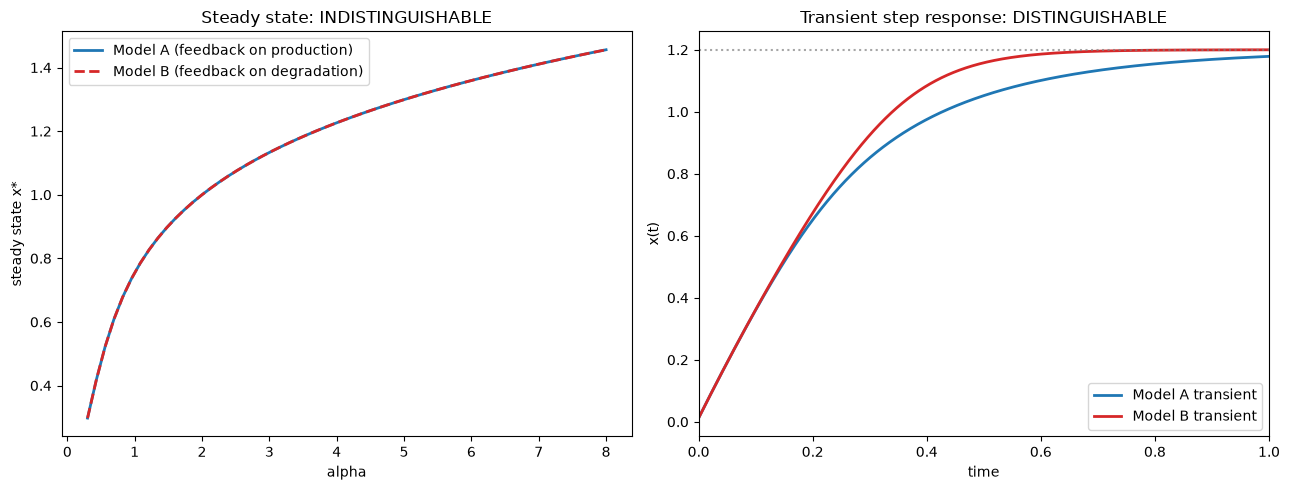

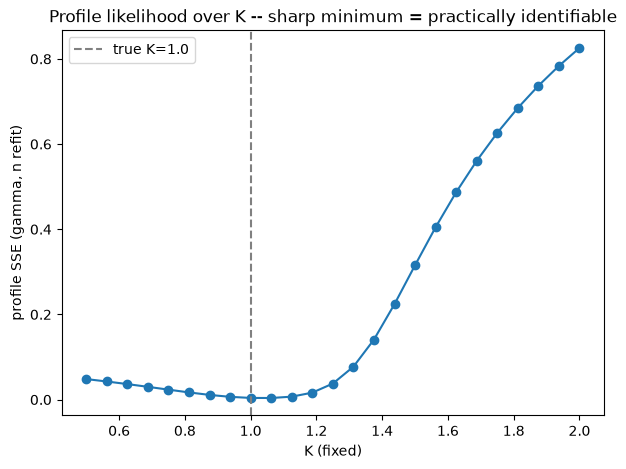

Exported results/hero_identifiability.png, results/profile_likelihood_K.png,
results/steady_state_comparison.csv, results/profile_likelihood_K.csv,
results/symbolic_identifiability_summary.txt


In [10]:
alphas_curve = np.linspace(0.3, 8, 60)
x_of_alpha_A = np.array([brentq(fA, 1e-9, 50, args=(a, K_val, n_val, gamma_val)) for a in alphas_curve])  # np.array([brentq(fA, 1e-9, 50, args=(a, K_val, n_val, gamma_val)) for a in alphas_curve])
x_of_alpha_B = np.array([brentq(fB, 1e-9, 50, args=(a, K_val, n_val, gamma_val)) for a in alphas_curve])  # np.array([brentq(fB, 1e-9, 50, args=(a, K_val, n_val, gamma_val)) for a in alphas_curve])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(alphas_curve, x_of_alpha_A, label="Model A (feedback on production)", color="tab:blue", lw=2)
axes[0].plot(alphas_curve, x_of_alpha_B, '--', label="Model B (feedback on degradation)", color="tab:red", lw=2)
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("steady state x*")
axes[0].set_title("Steady state: INDISTINGUISHABLE")
axes[0].legend()

axes[1].plot(t_eval, xA_traj, label="Model A transient", color="tab:blue", lw=2)
axes[1].plot(t_eval, xB_traj, label="Model B transient", color="tab:red", lw=2)
axes[1].axhline(xstar, color="gray", linestyle=":", alpha=0.7)
axes[1].set_xlim(0, 1.0)
axes[1].set_xlabel("time")
axes[1].set_ylabel("x(t)")
axes[1].set_title("Transient step response: DISTINGUISHABLE")
axes[1].legend()

plt.tight_layout()
plt.savefig("results/hero_identifiability.png", dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(Ks_grid, profile_sse, marker='o')
plt.axvline(K_true, color='gray', linestyle='--', label=f'true K={K_true}')
plt.xlabel("K (fixed)")
plt.ylabel("profile SSE (gamma, n refit)")
plt.title("Profile likelihood over K -- sharp minimum = practically identifiable")
plt.legend()
plt.savefig("results/profile_likelihood_K.png", dpi=150)
plt.show()

pd.DataFrame({"alpha": alphas_curve, "xstar_A": x_of_alpha_A, "xstar_B": x_of_alpha_B}).to_csv("results/steady_state_comparison.csv", index=False)
pd.DataFrame({"K": Ks_grid, "profile_sse": profile_sse}).to_csv("results/profile_likelihood_K.csv", index=False)
with open("results/symbolic_identifiability_summary.txt", "w") as f:
    f.write(f"Model A steady-state relation: alpha = {sp.simplify(alphaA_ss)}\n")
    f.write(f"Model B steady-state relation: alpha = {sp.simplify(alphaB_ss)}\n")
    f.write(f"Symbolic difference (steady state): {difference}\n\n")
    f.write(f"Model A linearization at steady state: {dfA_ss}\n")
    f.write(f"Model B linearization at steady state: {dfB_ss}\n")
    f.write(f"lamA (numeric, xstar={xstar}): {lamA:.6f}\n")
    f.write(f"lamB (numeric, xstar={xstar}): {lamB:.6f}\n")
    f.write(f"Fitted rateA: {rateA_fit:.6f}   Fitted rateB: {rateB_fit:.6f}\n")
print("Exported results/hero_identifiability.png, results/profile_likelihood_K.png,")
print("results/steady_state_comparison.csv, results/profile_likelihood_K.csv,")
print("results/symbolic_identifiability_summary.txt")
